<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab7_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q scikit-learn==1.5.2 scikeras==0.13.0

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from scikeras.wrappers import KerasClassifier

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load Pima Indians Diabetes Dataset

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

df = pd.read_csv(url, names=columns)

# Display first five records
print("First five records:")
display(df.head())

# Dataset information
print("\nDataset Information:")
print(df.info())

# Dataset shape
print("\nDataset Shape:", df.shape)

First five records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Dataset Shape: (768, 9)


Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


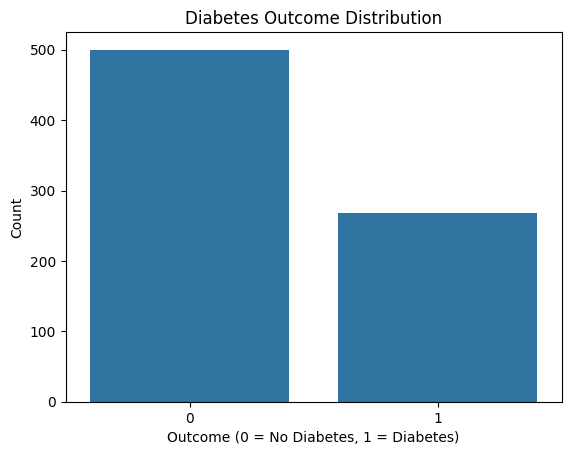

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check class distribution
print("\nOutcome Distribution:")
print(df['Outcome'].value_counts())

# Visualize outcome distribution
sns.countplot(x='Outcome', data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

In [5]:
# Replace invalid zero values with NaN

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

for col in zero_columns:
    df[col] = df[col].replace(0, np.nan)

# Check missing values after replacement
print("Missing values after replacing zeros:")
print(df.isnull().sum())

# Separate input and output variables
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Missing values after replacing zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Training data shape: (614, 8)
Testing data shape: (154, 8)


In [6]:
def create_model(
    meta,
    learning_rate=0.001,
    initializer='glorot_uniform',
    activation='relu',
    dropout_rate=0.2,
    neurons=16
):

    model = Sequential()

    # Input and hidden layer
    model.add(Dense(
        neurons,
        input_shape=(meta["n_features_in_"],),
        activation=activation,
        kernel_initializer=initializer
    ))

    # Dropout regularization
    model.add(Dropout(dropout_rate))

    # Output layer
    model.add(Dense(
        1,
        activation='sigmoid'
    ))

    # Compile model
    optimizer = Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [7]:
# Create Keras classifier

keras_model = KerasClassifier(
    model=create_model,
    verbose=0,
    random_state=42
)

# Create preprocessing and model pipeline

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', keras_model)
])

print("Deep Learning Pipeline Created Successfully!")

Deep Learning Pipeline Created Successfully!


In [8]:
param_grid = {
    # Tune batch size
    'classifier__batch_size': [16, 32],

    # Tune training epochs
    'classifier__epochs': [50, 100],

    # Tune learning rate
    'classifier__model__learning_rate': [0.001, 0.01],

    # Tune weight initialization
    'classifier__model__initializer': [
        'glorot_uniform',
        'he_uniform'
    ],

    # Tune activation functions
    'classifier__model__activation': [
        'relu',
        'tanh'
    ],

    # Tune dropout regularization
    'classifier__model__dropout_rate': [
        0.0,
        0.2
    ],

    # Tune number of hidden neurons
    'classifier__model__neurons': [
        8,
        16
    ]
}

print("Grid Search Parameters:")
for parameter, values in param_grid.items():
    print(parameter, ":", values)

Grid Search Parameters:
classifier__batch_size : [16, 32]
classifier__epochs : [50, 100]
classifier__model__learning_rate : [0.001, 0.01]
classifier__model__initializer : ['glorot_uniform', 'he_uniform']
classifier__model__activation : ['relu', 'tanh']
classifier__model__dropout_rate : [0.0, 0.2]
classifier__model__neurons : [8, 16]


In [9]:
# Create Stratified K-Fold Cross Validation

kfold = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create Grid Search

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring='accuracy',
    verbose=1,
    n_jobs=1
)

# Fit Grid Search on training data

print("Starting Grid Search...")

grid_result = grid.fit(X_train, y_train)

print("\nGrid Search Completed Successfully!")

Starting Grid Search...
Fitting 3 folds for each of 128 candidates, totalling 384 fits



Grid Search Completed Successfully!


In [10]:
print("Best Accuracy:", grid_result.best_score_)

print("\nBest Hyperparameters:")

for parameter, value in grid_result.best_params_.items():
    print(parameter, ":", value)

print("\nBest Model:")
print(grid_result.best_estimator_)

Best Accuracy: 0.7915670333173921

Best Hyperparameters:
classifier__batch_size : 16
classifier__epochs : 100
classifier__model__activation : tanh
classifier__model__dropout_rate : 0.0
classifier__model__initializer : he_uniform
classifier__model__learning_rate : 0.001
classifier__model__neurons : 8

Best Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 KerasClassifier(batch_size=16, epochs=100, model=<function create_model at 0x7d32e67e2b60>, model__activation='tanh', model__dropout_rate=0.0, model__initializer='he_uniform', model__learning_rate=0.001, model__neurons=8, random_state=42, verbose=0))])


In [11]:
# Get best model
best_model = grid_result.best_estimator_

# Predict test data
y_pred = best_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.6883116883116883

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.76      0.76       100
           1       0.56      0.56      0.56        54

    accuracy                           0.69       154
   macro avg       0.66      0.66      0.66       154
weighted avg       0.69      0.69      0.69       154



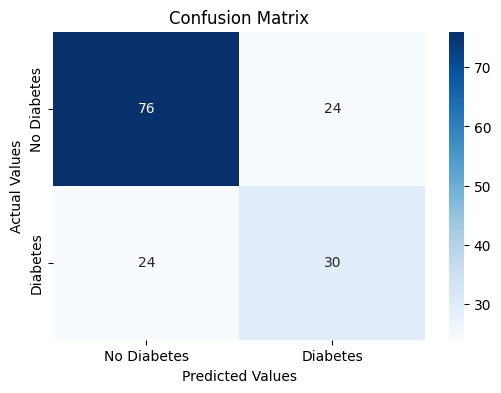

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [13]:
results = pd.DataFrame(grid_result.cv_results_)

# Sort results by mean test score
results = results.sort_values(
    by='mean_test_score',
    ascending=False
)

# Display top 10 combinations
display(
    results[
        ['mean_test_score', 'std_test_score', 'params']
    ].head(10)
)

,mean_test_score,std_test_score,params
52,0.791567,0.017577,"{'classifier__batch_size': 16, 'classifier__ep..."
20,0.788283,0.005734,"{'classifier__batch_size': 16, 'classifier__ep..."
121,0.788267,0.012271,"{'classifier__batch_size': 32, 'classifier__ep..."
112,0.786641,0.002583,"{'classifier__batch_size': 32, 'classifier__ep..."
116,0.785031,0.007560,"{'classifier__batch_size': 32, 'classifier__ep..."
80,0.785031,0.010234,"{'classifier__batch_size': 32, 'classifier__ep..."
57,0.785031,0.010234,"{'classifier__batch_size': 16, 'classifier__ep..."
16,0.785015,0.000496,"{'classifier__batch_size': 16, 'classifier__ep..."
104,0.783413,0.016265,"{'classifier__batch_size': 32, 'classifier__ep..."
117,0.783397,0.012637,"{'classifier__batch_size': 32, 'classifier__ep..."


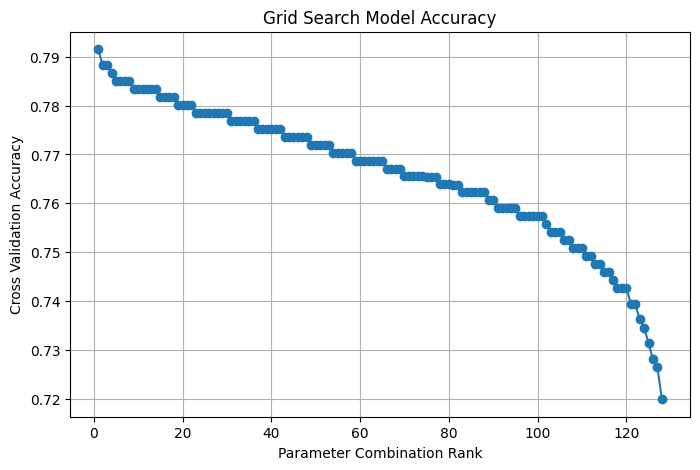

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(results) + 1),
    results['mean_test_score'].values,
    marker='o'
)

plt.title("Grid Search Model Accuracy")
plt.xlabel("Parameter Combination Rank")
plt.ylabel("Cross Validation Accuracy")

plt.grid(True)
plt.show()

In [15]:
print("========== LAB ASSIGNMENT 7 ==========")
print("Deep Learning Grid Search")
print("Dataset: Pima Indians Diabetes")

print("\nBest Cross Validation Accuracy:",
      round(grid_result.best_score_ * 100, 2), "%")

print("Final Testing Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nBest Hyperparameters:")
for key, value in grid_result.best_params_.items():
    print(key, "=", value)

print("\nAssignment Completed Successfully!")

========== LAB ASSIGNMENT 7 ==========
Deep Learning Grid Search
Dataset: Pima Indians Diabetes

Best Cross Validation Accuracy: 79.16 %
Final Testing Accuracy: 68.83 %

Best Hyperparameters:
classifier__batch_size = 16
classifier__epochs = 100
classifier__model__activation = tanh
classifier__model__dropout_rate = 0.0
classifier__model__initializer = he_uniform
classifier__model__learning_rate = 0.001
classifier__model__neurons = 8

Assignment Completed Successfully!
